# PART A: Decision Tree from Scratch

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score

In [2]:
# Load the dataset

columns = [
    "variance",
    "skewness",
    "curtosis",
    "entropy",
    "class"
]

df = pd.read_csv(
    "data_banknote_authentication.txt",
    header=None,
    names=columns
)

print("Dataset shape:", df.shape)

display(df.head())

print("\nMissing values:")
print(df.isnull().sum())

print("\nClass distribution:")
print(df["class"].value_counts().sort_index())

Dataset shape: (1372, 5)


,variance,skewness,curtosis,entropy,class
0,3.62160,8.6661,-2.8073,-0.44699,0
1,4.54590,8.1674,-2.4586,-1.46210,0
2,3.86600,-2.6383,1.9242,0.10645,0
3,3.45660,9.5228,-4.0112,-3.59440,0
4,0.32924,-4.4552,4.5718,-0.98880,0



Missing values:
variance    0
skewness    0
curtosis    0
entropy     0
class       0
dtype: int64

Class distribution:
class
0    762
1    610
Name: count, dtype: int64


In [3]:
# Select two features

feature_names = ["variance", "skewness"]

X = df[feature_names].to_numpy(dtype=float)
y = df["class"].to_numpy(dtype=int)

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)

print("Training class distribution:")
print(pd.Series(y_train).value_counts().sort_index())

Training features: (1097, 2)
Testing features: (275, 2)
Training class distribution:
0    609
1    488
Name: count, dtype: int64


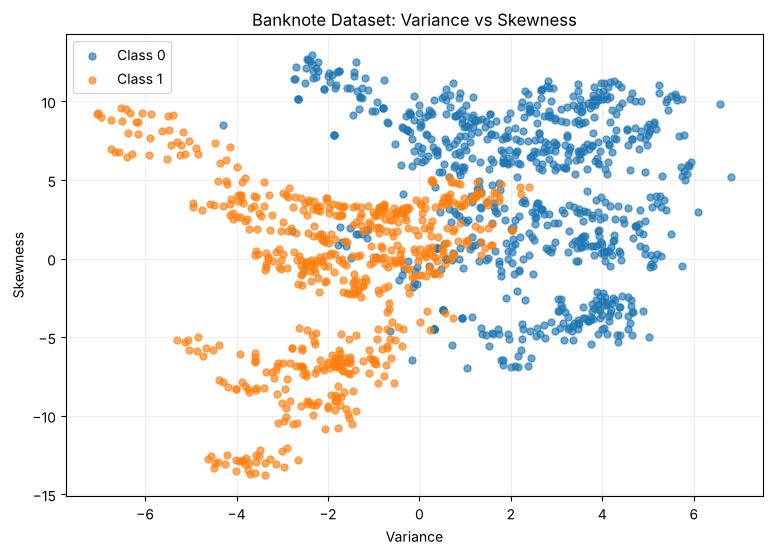

In [4]:
# Scatter plot

plt.figure(figsize=(9, 6))

for class_label in np.unique(y):
    mask = y == class_label

    plt.scatter(
        X[mask, 0],
        X[mask, 1],
        label=f"Class {class_label}",
        alpha=0.65,
        s=25
    )

plt.xlabel("Variance")
plt.ylabel("Skewness")
plt.title("Banknote Dataset: Variance vs Skewness")
plt.legend()
plt.grid(alpha=0.2)
plt.show()

In [5]:
# Gini impurity from scratch

def gini_impurity(y):
    if len(y) == 0:
        return 0.0

    _, counts = np.unique(y, return_counts=True)
    probabilities = counts / len(y)

    return 1.0 - np.sum(probabilities ** 2)

In [6]:
# Entropy from scratch

def entropy(y):
    if len(y) == 0:
        return 0.0

    _, counts = np.unique(y, return_counts=True)
    probabilities = counts / len(y)

    return float(-np.sum(
        probabilities * np.log2(probabilities)
    )) + 0.0

In [7]:
# Test impurity calculations

print("Gini of training target:", gini_impurity(y_train))
print("Entropy of training target:", entropy(y_train))

print("\nPure-node Gini:", gini_impurity(np.array([0, 0, 0])))
print("Pure-node entropy:", entropy(np.array([0, 0, 0])))

Gini of training target: 0.4939168645074119
Entropy of training target: 0.9912060080005995

Pure-node Gini: 0.0
Pure-node entropy: 0.0


In [8]:
# Calculate weighted child impurity

def weighted_impurity(y_left, y_right, criterion="gini"):
    n = len(y_left) + len(y_right)

    if n == 0:
        return 0.0

    impurity_function = (
        gini_impurity if criterion == "gini" else entropy
    )

    return (
        len(y_left) / n * impurity_function(y_left)
        + len(y_right) / n * impurity_function(y_right)
    )

In [9]:
# Find the best split from scratch

def find_best_split(X, y, criterion="gini"):
    n_samples, n_features = X.shape

    if n_samples < 2:
        return None, None, None

    impurity_function = (
        gini_impurity if criterion == "gini" else entropy
    )

    parent_impurity = impurity_function(y)

    best_gain = 0.0
    best_feature = None
    best_threshold = None

    for feature_idx in range(n_features):
        values = np.unique(X[:, feature_idx])

        if len(values) < 2:
            continue

        thresholds = (
            values[:-1] + values[1:]
        ) / 2.0

        for threshold in thresholds:
            left_mask = X[:, feature_idx] <= threshold
            right_mask = ~left_mask

            y_left = y[left_mask]
            y_right = y[right_mask]

            if len(y_left) == 0 or len(y_right) == 0:
                continue

            child_impurity = weighted_impurity(
                y_left,
                y_right,
                criterion
            )

            gain = parent_impurity - child_impurity

            if gain > best_gain:
                best_gain = gain
                best_feature = feature_idx
                best_threshold = threshold

    if best_feature is None:
        return None, None, 0.0

    return best_feature, best_threshold, best_gain

In [10]:
# Test the best split

feature_idx, threshold, gain = find_best_split(
    X_train,
    y_train,
    criterion="gini"
)

if feature_idx is not None:
    print("Best feature:", feature_names[feature_idx])
    print("Best threshold:", threshold)
    print("Gini impurity reduction:", gain)
else:
    print("No valid split found.")

Best feature: variance
Best threshold: 0.7651
Gini impurity reduction: 0.24209450956617234


In [11]:
# Decision Tree node

class TreeNode:
    def __init__(
        self,
        feature_idx=None,
        threshold=None,
        left=None,
        right=None,
        prediction=None,
        gain=None
    ):
        self.feature_idx = feature_idx
        self.threshold = threshold
        self.left = left
        self.right = right
        self.prediction = prediction
        self.gain = gain

    @property
    def is_leaf(self):
        return self.prediction is not None

In [12]:
# Recursive tree construction

def majority_class(y):
    classes, counts = np.unique(y, return_counts=True)
    return classes[np.argmax(counts)]

def build_tree(
    X,
    y,
    criterion="gini",
    max_depth=5,
    min_samples_split=2,
    depth=0
):
    # Stop if the node is pure.
    if len(np.unique(y)) == 1:
        return TreeNode(prediction=int(y[0]))

    # Stop if the depth or sample-size limit is reached.
    if depth >= max_depth or len(y) < min_samples_split:
        return TreeNode(prediction=int(majority_class(y)))

    # Find the best split.
    feature_idx, threshold, gain = find_best_split(
        X,
        y,
        criterion=criterion
    )

    # Stop if no useful split exists.
    if feature_idx is None or gain <= 0:
        return TreeNode(prediction=int(majority_class(y)))

    left_mask = X[:, feature_idx] <= threshold
    right_mask = ~left_mask

    # Build both child subtrees recursively.
    left_child = build_tree(
        X[left_mask],
        y[left_mask],
        criterion,
        max_depth,
        min_samples_split,
        depth + 1
    )

    right_child = build_tree(
        X[right_mask],
        y[right_mask],
        criterion,
        max_depth,
        min_samples_split,
        depth + 1
    )

    return TreeNode(
        feature_idx=feature_idx,
        threshold=threshold,
        left=left_child,
        right=right_child,
        gain=gain
    )

In [13]:
# Train the manual decision tree

manual_tree = build_tree(
    X_train,
    y_train,
    criterion="gini",
    max_depth=5,
    min_samples_split=2
)

print("Manual decision tree trained.")

Manual decision tree trained.


In [ ]:
# Predict one sample and multiple samples

def predict_one(node, x):
    if node.is_leaf:
        return node.prediction

    if x[node.feature_idx] <= node.threshold:
        return predict_one(node.left, x)

    return predict_one(node.right, x)

def predict_tree(root, X):
    return np.array([
        predict_one(root, x)
        for x in X
    ], dtype=int)

In [15]:
# Evaluate manual tree

y_pred_manual = predict_tree(manual_tree, X_test)
manual_accuracy = accuracy_score(y_test, y_pred_manual)
print(f"Manual Tree Test Accuracy: {manual_accuracy:.4f}")

Manual Tree Test Accuracy: 0.9309


In [16]:
# Train Scikit-learn decision tree

sklearn_tree = DecisionTreeClassifier(
    criterion="gini",
    max_depth=5,
    min_samples_split=2,
    random_state=42
)

sklearn_tree.fit(X_train, y_train)
y_pred_sklearn = sklearn_tree.predict(X_test)
sklearn_accuracy = accuracy_score(y_test, y_pred_sklearn)

print(f"Manual Tree Accuracy:    {manual_accuracy:.4f}")
print(f"Scikit-learn Accuracy:   {sklearn_accuracy:.4f}")
print(
    "Prediction agreement:",
    f"{np.mean(y_pred_manual == y_pred_sklearn):.4f}"
)

Manual Tree Accuracy:    0.9309
Scikit-learn Accuracy:   0.9309
Prediction agreement: 1.0000


In [17]:
# Decision-boundary plotting function

def plot_tree_boundary(
    model_predict,
    X,
    y,
    title,
    feature_names
):
    x_min, x_max = X[:, 0].min() - 0.5, X[:, 0].max() + 0.5
    y_min, y_max = X[:, 1].min() - 0.5, X[:, 1].max() + 0.5

    xx, yy = np.meshgrid(
        np.linspace(x_min, x_max, 300),
        np.linspace(y_min, y_max, 300)
    )

    grid = np.c_[xx.ravel(), yy.ravel()]
    Z = model_predict(grid).reshape(xx.shape)

    plt.figure(figsize=(8, 6))
    plt.contourf(xx, yy, Z, alpha=0.25, levels=[-0.5, 0.5, 1.5])

    for class_label in np.unique(y):
        mask = y == class_label
        plt.scatter(
            X[mask, 0],
            X[mask, 1],
            label=f"Class {class_label}",
            edgecolor="black",
            linewidth=0.3,
            s=20
        )

    plt.xlabel(feature_names[0].title())
    plt.ylabel(feature_names[1].title())
    plt.title(title)
    plt.legend()
    plt.grid(alpha=0.15)
    plt.show()

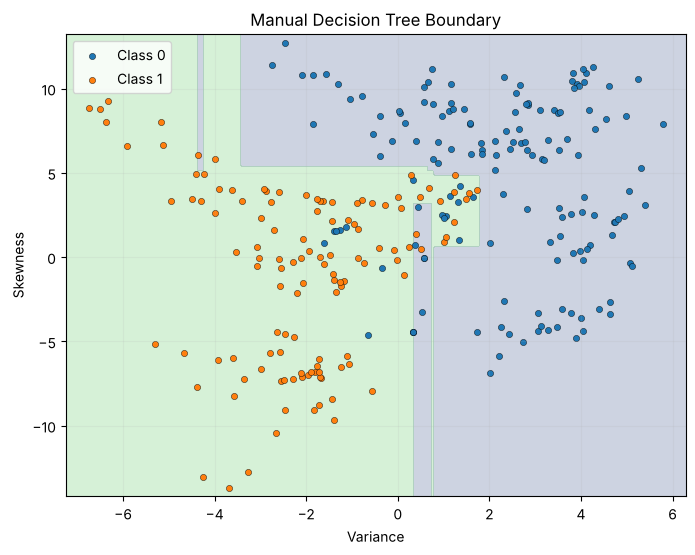

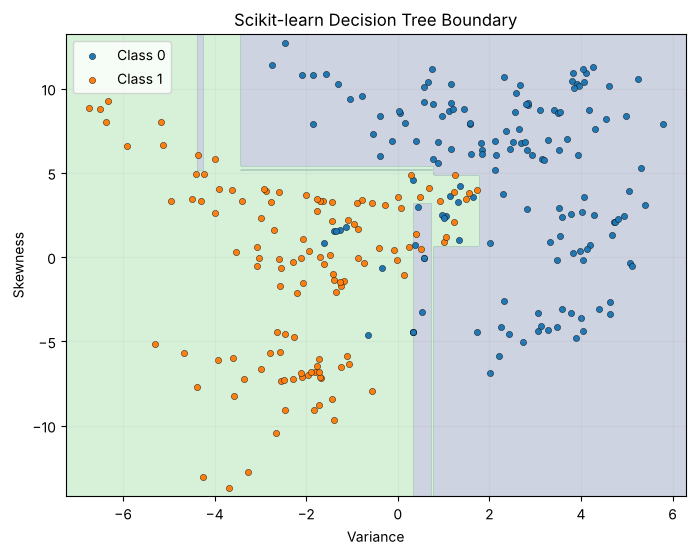

In [18]:
# Plot both trees

plot_tree_boundary(
    lambda points: predict_tree(manual_tree, points),
    X_test,
    y_test,
    "Manual Decision Tree Boundary",
    feature_names
)

plot_tree_boundary(
    lambda points: sklearn_tree.predict(points),
    X_test,
    y_test,
    "Scikit-learn Decision Tree Boundary",
    feature_names
)

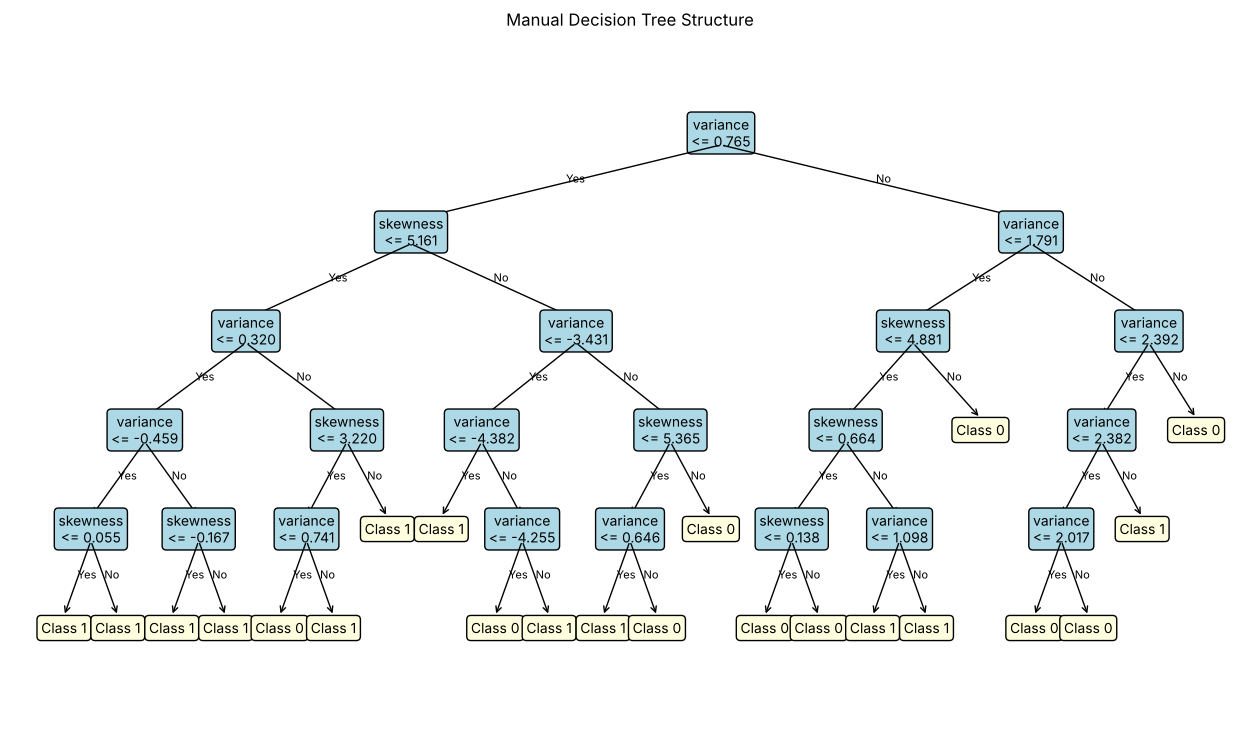

In [19]:
# Plot manual tree structure

def draw_manual_tree(node, feature_names, ax=None):
    if ax is None:
        fig, ax = plt.subplots(figsize=(16, 9))
        ax.axis("off")
        draw_manual_tree(node, feature_names, ax)
        plt.title("Manual Decision Tree Structure")
        plt.show()
        return

    positions = {}
    leaf_counter = [0]

    def assign_positions(current, depth=0):
        if current.is_leaf:
            x = leaf_counter[0]
            leaf_counter[0] += 1
        else:
            left_x = assign_positions(current.left, depth + 1)
            right_x = assign_positions(current.right, depth + 1)
            x = (left_x + right_x) / 2

        positions[id(current)] = (x, -depth)
        return x

    def draw_edges(current):
        x, y_pos = positions[id(current)]

        if current.is_leaf:
            label = f"Class {current.prediction}"
            ax.text(
                x, y_pos, label,
                ha="center", va="center",
                bbox=dict(boxstyle="round", fc="lightyellow")
            )
            return

        label = (
            f"{feature_names[current.feature_idx]}\n"
            f"<= {current.threshold:.3f}"
        )

        ax.text(
            x, y_pos, label,
            ha="center", va="center",
            bbox=dict(boxstyle="round", fc="lightblue")
        )

        for child, edge_label in [
            (current.left, "Yes"),
            (current.right, "No")
        ]:
            cx, cy = positions[id(child)]
            ax.annotate(
                "",
                xy=(cx, cy + 0.12),
                xytext=(x, y_pos - 0.12),
                arrowprops=dict(arrowstyle="->")
            )
            ax.text(
                (x + cx) / 2,
                (y_pos + cy) / 2,
                edge_label,
                fontsize=8
            )
            draw_edges(child)

    assign_positions(node)
    draw_edges(node)

    ax.set_xlim(-1, leaf_counter[0])
    tree_depth = max(-p[1] for p in positions.values())
    ax.set_ylim(-tree_depth - 1, 1)


draw_manual_tree(manual_tree, feature_names)

In [20]:
# Criterion and depth experiment

results = []

for criterion in ["gini", "entropy"]:
    for depth in [1, 2, 3, 5, 10, None]:

        # Manual implementation
        manual_model = build_tree(
            X_train,
            y_train,
            criterion=criterion,
            max_depth=depth if depth is not None else len(X_train),
            min_samples_split=2
        )

        manual_predictions = predict_tree(manual_model, X_test)

        # Scikit-learn comparison
        sklearn_model = DecisionTreeClassifier(
            criterion=criterion,
            max_depth=depth,
            min_samples_split=2,
            random_state=42
        )

        sklearn_model.fit(X_train, y_train)
        sklearn_predictions = sklearn_model.predict(X_test)

        results.append({
            "Criterion": criterion,
            "Max Depth": str(depth),
            "Manual Accuracy": accuracy_score(
                y_test, manual_predictions
            ),
            "Sklearn Accuracy": accuracy_score(
                y_test, sklearn_predictions
            ),
            "Manual Agreement": np.mean(
                manual_predictions == sklearn_predictions
            ),
            "Sklearn Leaves": sklearn_model.get_n_leaves(),
            "Sklearn Depth": sklearn_model.get_depth()
        })

results_df = pd.DataFrame(results)

display(
    results_df.round(4)
)

,Criterion,Max Depth,Manual Accuracy,Sklearn Accuracy,Manual Agreement,Sklearn Leaves,Sklearn Depth
0,gini,1,0.8291,0.8291,1.0000,2,1
1,gini,2,0.8764,0.8764,1.0000,4,2
2,gini,3,0.9091,0.9091,1.0000,8,3
3,gini,5,0.9309,0.9309,1.0000,22,5
4,gini,10,0.9200,0.9236,0.9964,65,10
5,gini,None,0.9200,0.9200,0.9927,74,14
6,entropy,1,0.8291,0.8291,1.0000,2,1
7,entropy,2,0.8764,0.8764,1.0000,4,2
8,entropy,3,0.9091,0.9091,1.0000,7,3
9,entropy,5,0.9345,0.9345,1.0000,18,5


# Part B: Linear SVM from Scratch

In [21]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score
import time
from sklearn.preprocessing import StandardScaler


In [22]:
# Convert labels from {0, 1} to {-1, +1}
y_train_svm = np.where(np.asarray(y_train) == 1, 1, -1)
y_test_svm = np.where(np.asarray(y_test) == 1, 1, -1)

# Standardize features (fit on training data only, to avoid leakage).
# SVMs are scale-sensitive, unlike decision trees.
scaler_2d = StandardScaler()
X_train_svm = scaler_2d.fit_transform(np.asarray(X_train, dtype=float))
X_test_svm = scaler_2d.transform(np.asarray(X_test, dtype=float))

def hinge_loss(X, y, w, b):
    margins = y * (X @ w + b)
    return np.mean(np.maximum(0, 1 - margins))

In [23]:
def train_linear_svm(
    X, y, learning_rate=0.001, C=1.0, epochs=2000
):
    n_samples, n_features = X.shape

    w = np.zeros(n_features)
    b = 0.0
    loss_history = []

    for epoch in range(epochs):
        # Margin for every training observation
        margins = y * (X @ w + b)

        # Points inside the margin or misclassified
        violating = margins < 1

        # Objective: 0.5*||w||^2 + C*sum(hinge) (same form as sklearn's SVC)
        # Gradient of regularization term
        dw = w.copy()
        db = 0.0

        # Add hinge-loss contributions
        if np.any(violating):
            dw -= C * np.sum(
                (y[violating, None] * X[violating]), axis=0
            )
            db -= C * np.sum(y[violating])

        # Update parameters
        w -= learning_rate * dw
        b -= learning_rate * db

        # Record objective value
        current_margins = y * (X @ w + b)
        current_loss = (
            0.5 * np.dot(w, w)
            + C * np.sum(np.maximum(0, 1 - current_margins))
        )
        loss_history.append(current_loss)

    return w, b, loss_history

In [24]:
start_time = time.perf_counter()

w_manual, b_manual, loss_history = train_linear_svm(
    X_train_svm,
    y_train_svm,
    learning_rate=0.001,
    C=1.0,
    epochs=2000
)

manual_svm_time = time.perf_counter() - start_time

def predict_linear_svm(X, w, b):
    scores = X @ w + b
    return np.where(scores >= 0, 1, -1)

y_train_pred_manual_svm = predict_linear_svm(
    X_train_svm, w_manual, b_manual
)

manual_svm_train_accuracy = accuracy_score(
    y_train_svm, y_train_pred_manual_svm
)

y_pred_manual_svm = predict_linear_svm(
    X_test_svm, w_manual, b_manual
)

manual_svm_accuracy = accuracy_score(
    y_test_svm, y_pred_manual_svm
)

print("Manual Linear SVM")
print("Weights:", w_manual)
print("Bias:", b_manual)
print(f"Train accuracy: {manual_svm_train_accuracy:.4f}")
print(f"Test accuracy: {manual_svm_accuracy:.4f}")
print(f"Training time: {manual_svm_time:.6f} seconds")

Manual Linear SVM
Weights: [-2.00791504 -1.25658803]
Bias: -0.22099999999999997
Train accuracy: 0.8806
Test accuracy: 0.8764
Training time: 0.116704 seconds


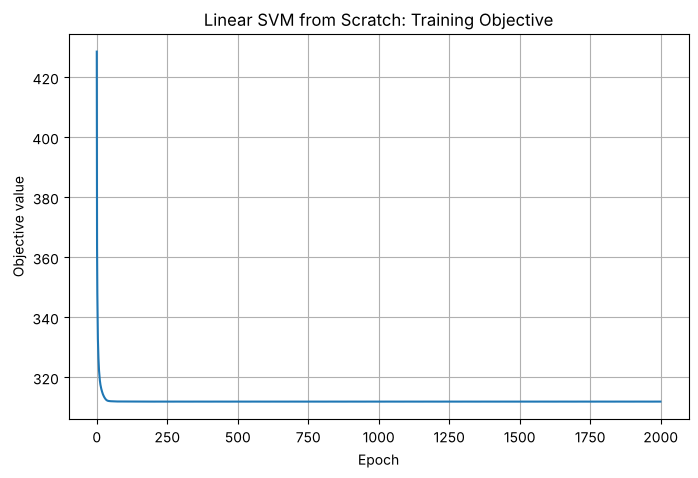

In [25]:
# loss curve
plt.figure(figsize=(8, 5))
plt.plot(loss_history)
plt.xlabel("Epoch")
plt.ylabel("Objective value")
plt.title("Linear SVM from Scratch: Training Objective")
plt.grid(True)
plt.show()

In [26]:
# compare with sklearn
start_time = time.perf_counter()

svm_sklearn = SVC(kernel="linear", C=1.0)
svm_sklearn.fit(X_train_svm, y_train_svm)

sklearn_svm_time = time.perf_counter() - start_time

y_pred_sklearn_svm = svm_sklearn.predict(X_test_svm)

sklearn_svm_accuracy = accuracy_score(
    y_test_svm, y_pred_sklearn_svm
)

print("Scikit-learn Linear SVM")
print(f"Test accuracy: {sklearn_svm_accuracy:.4f}")
print(f"Training time: {sklearn_svm_time:.6f} seconds")

Scikit-learn Linear SVM
Test accuracy: 0.8764
Training time: 0.010140 seconds


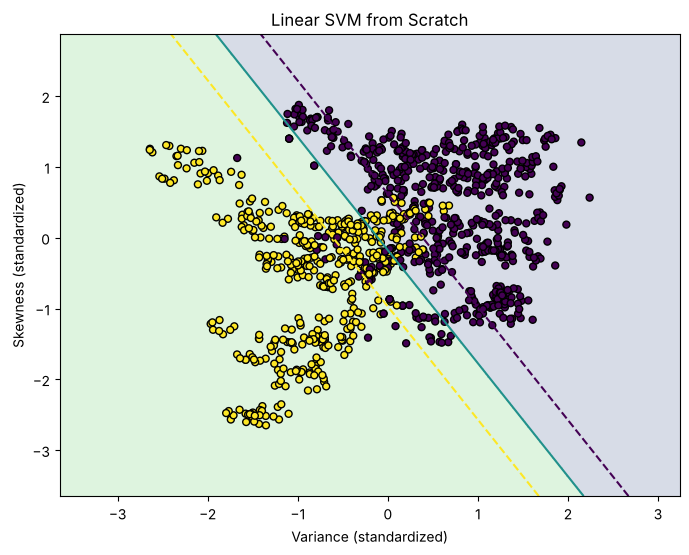

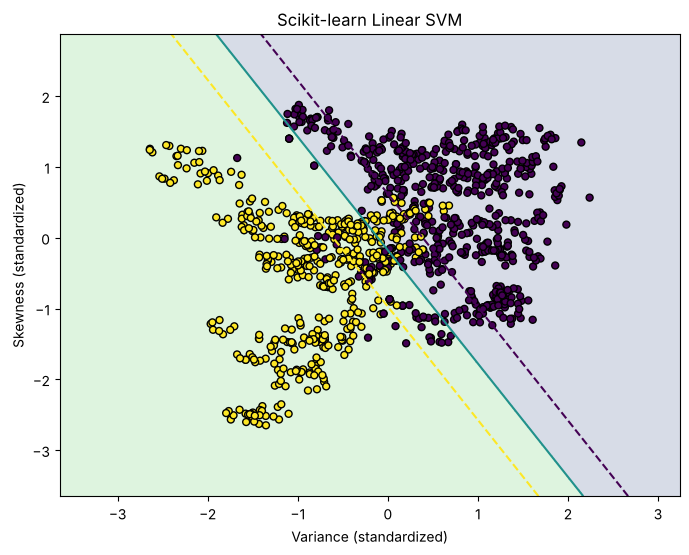

In [27]:
def plot_svm_boundary(X, y, model_type, title, w=None, b=None):
    x_min, x_max = X[:, 0].min() - 1, X[:, 0].max() + 1
    y_min, y_max = X[:, 1].min() - 1, X[:, 1].max() + 1

    xx, yy = np.meshgrid(
        np.linspace(x_min, x_max, 300),
        np.linspace(y_min, y_max, 300)
    )
    grid = np.c_[xx.ravel(), yy.ravel()]

    if model_type == "manual":
        scores = grid @ w + b
    else:
        scores = model_type.decision_function(grid)

    scores = scores.reshape(xx.shape)

    plt.figure(figsize=(8, 6))
    plt.contourf(xx, yy, scores >= 0, alpha=0.2, levels=[-0.5, 0.5, 1.5])
    plt.contour(
        xx, yy, scores,
        levels=[-1, 0, 1],
        linestyles=["--", "-", "--"]
    )
    plt.scatter(X[:, 0], X[:, 1], c=y, edgecolors="black", s=25)
    plt.xlabel("Variance (standardized)")
    plt.ylabel("Skewness (standardized)")
    plt.title(title)
    plt.show()


plot_svm_boundary(
    X_train_svm, y_train_svm,
    "manual",
    "Linear SVM from Scratch",
    w=w_manual, b=b_manual
)

plot_svm_boundary(
    X_train_svm, y_train_svm,
    svm_sklearn,
    "Scikit-learn Linear SVM"
)

In [28]:
# Training accuracy
y_train_pred_manual = predict_linear_svm(
    X_train_svm, w_manual, b_manual
)
manual_svm_train_accuracy = accuracy_score(
    y_train_svm, y_train_pred_manual
)

y_train_pred_sklearn = svm_sklearn.predict(X_train_svm)
sklearn_svm_train_accuracy = accuracy_score(
    y_train_svm, y_train_pred_sklearn
)

# Comparison table
print(f"{'Metric':<25}{'Manual SVM':>15}{'Sklearn SVM':>15}")

print(
    f"{'Training accuracy':<25}"
    f"{manual_svm_train_accuracy:>15.4f}"
    f"{sklearn_svm_train_accuracy:>15.4f}"
)

print(
    f"{'Test accuracy':<25}"
    f"{manual_svm_accuracy:>15.4f}"
    f"{sklearn_svm_accuracy:>15.4f}"
)

print(
    f"{'Training time (sec)':<25}"
    f"{manual_svm_time:>15.6f}"
    f"{sklearn_svm_time:>15.6f}"
)

Metric                        Manual SVM    Sklearn SVM
Training accuracy                 0.8806         0.8806
Test accuracy                     0.8764         0.8764
Training time (sec)             0.116704       0.010140


# Part C: Nonlinear SVM Kernels

In [29]:
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score
import pandas as pd
import time
import numpy as np
import matplotlib.pyplot as plt


In [30]:
# Kernel configurations
kernel_models = {
    "Linear": SVC(kernel="linear", C=1.0),
    "Polynomial (degree 3)": SVC(
        kernel="poly", degree=3, C=1.0, gamma="scale"
    ),
    "RBF": SVC(kernel="rbf", C=1.0, gamma="scale")
}

kernel_results = []
trained_kernel_models = {}

for name, model in kernel_models.items():
    start_time = time.perf_counter()

    model.fit(X_train_svm, y_train_svm)

    training_time = time.perf_counter() - start_time

    # Training accuracy
    y_train_pred = model.predict(X_train_svm)
    training_accuracy = accuracy_score(y_train_svm, y_train_pred)

    # Test accuracy
    y_test_pred = model.predict(X_test_svm)
    test_accuracy = accuracy_score(y_test_svm, y_test_pred)

    kernel_results.append({
        "Kernel": name,
        "Training Accuracy": training_accuracy,
        "Test Accuracy": test_accuracy,
        "Training Time (seconds)": training_time
    })

    trained_kernel_models[name] = model

kernel_results_df = pd.DataFrame(kernel_results)

display(kernel_results_df.round(4))

,Kernel,Training Accuracy,Test Accuracy,Training Time (seconds)
0,Linear,0.8806,0.8764,0.0105
1,Polynomial (degree 3),0.8259,0.8545,0.0101
2,RBF,0.9316,0.9236,0.0066


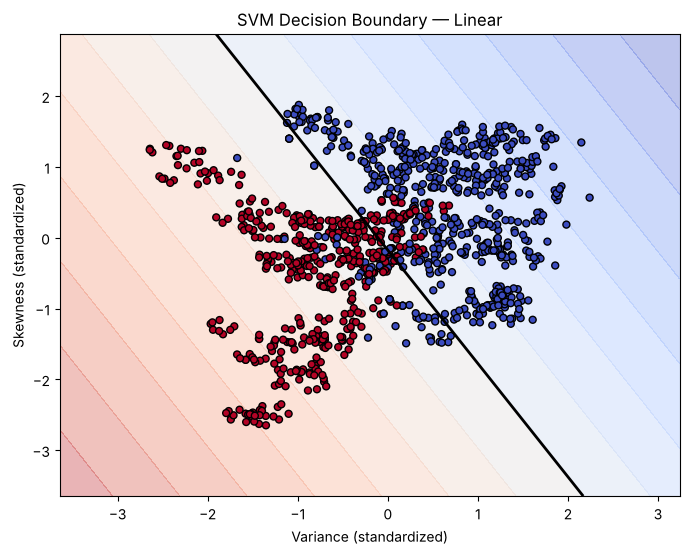

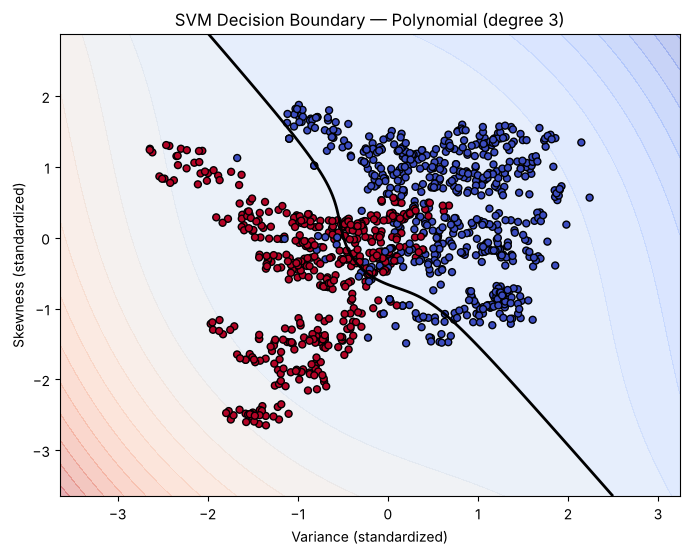

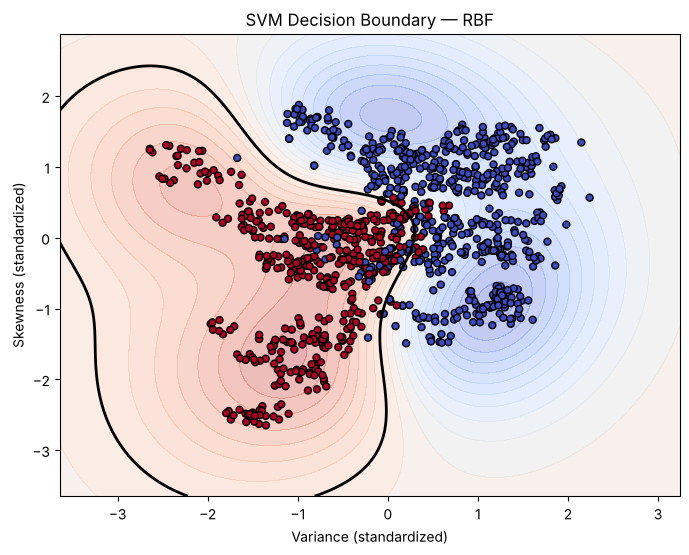

In [31]:
def plot_kernel_boundary(X, y, model, title):
    x_min, x_max = X[:, 0].min() - 1, X[:, 0].max() + 1
    y_min, y_max = X[:, 1].min() - 1, X[:, 1].max() + 1

    xx, yy = np.meshgrid(
        np.linspace(x_min, x_max, 300),
        np.linspace(y_min, y_max, 300)
    )

    grid = np.c_[xx.ravel(), yy.ravel()]
    scores = model.decision_function(grid).reshape(xx.shape)

    plt.figure(figsize=(8, 6))
    plt.contourf(
        xx, yy, scores,
        levels=20, cmap="coolwarm", alpha=0.35
    )
    plt.contour(
        xx, yy, scores,
        levels=[0], colors="black", linewidths=2
    )
    plt.scatter(
        X[:, 0], X[:, 1],
        c=y, cmap="coolwarm", edgecolors="black", s=25
    )

    plt.xlabel("Variance (standardized)")
    plt.ylabel("Skewness (standardized)")
    plt.title(title)
    plt.show()


for name, model in trained_kernel_models.items():
    plot_kernel_boundary(
        X_train_svm,
        y_train_svm,
        model,
        f"SVM Decision Boundary — {name}"
    )

In [32]:
kernel_results_df = kernel_results_df.sort_values(
    by="Test Accuracy", ascending=False
).reset_index(drop=True)

display(kernel_results_df.round(4))

best_kernel = kernel_results_df.iloc[0]["Kernel"]
best_accuracy = kernel_results_df.iloc[0]["Test Accuracy"]

print(f"Best kernel by test accuracy: {best_kernel}")
print(f"Test accuracy: {best_accuracy:.4f}")

,Kernel,Training Accuracy,Test Accuracy,Training Time (seconds)
0,RBF,0.9316,0.9236,0.0066
1,Linear,0.8806,0.8764,0.0105
2,Polynomial (degree 3),0.8259,0.8545,0.0101


Best kernel by test accuracy: RBF
Test accuracy: 0.9236


# Part D: Final Comparison

In [33]:
import numpy as np
import pandas as pd
import time
from sklearn.preprocessing import StandardScaler

from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.svm import SVC
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

In [34]:
# Use all four features
X_all = df[["variance", "skewness", "curtosis", "entropy"]].to_numpy(
    dtype=float
)
y_all = df["class"].to_numpy(dtype=int)

# Same 80:20 stratified split for both models
X_train_all, X_test_all, y_train_all, y_test_all = train_test_split(
    X_all,
    y_all,
    test_size=0.2,
    random_state=42,
    stratify=y_all
)

# Standardized copies for the SVMs (fit on training data only)
scaler_all = StandardScaler()
X_train_all_s = scaler_all.fit_transform(X_train_all)
X_test_all_s = scaler_all.transform(X_test_all)

print("Training samples:", len(X_train_all))
print("Testing samples:", len(X_test_all))
print("Number of features:", X_train_all.shape[1])

Training samples: 1097
Testing samples: 275
Number of features: 4


In [35]:
start_time = time.perf_counter()

manual_tree_all = build_tree(
    X_train_all,
    y_train_all,
    criterion="gini",
    max_depth=5,
    min_samples_split=2
)

manual_tree_time = time.perf_counter() - start_time

y_pred_manual_tree = predict_tree(
    manual_tree_all,
    X_test_all
)

print("Manual Decision Tree trained.")
print(f"Training time: {manual_tree_time:.6f} seconds")

Manual Decision Tree trained.
Training time: 0.856068 seconds


In [36]:
y_train_all_svm = np.where(y_train_all == 1, 1, -1)
y_test_all_svm = np.where(y_test_all == 1, 1, -1)

start_time = time.perf_counter()

w_all, b_all, svm_loss_history = train_linear_svm(
    X_train_all_s,
    y_train_all_svm,
    learning_rate=0.001,
    C=1.0,
    epochs=2000
)

manual_svm_all_time = time.perf_counter() - start_time

y_pred_manual_svm_all = predict_linear_svm(
    X_test_all_s, w_all, b_all
)

print("Manual Linear SVM trained.")
print(f"Training time: {manual_svm_all_time:.6f} seconds")

Manual Linear SVM trained.
Training time: 0.151950 seconds


In [37]:
# Scikit-learn Decision Tree
start_time = time.perf_counter()

sklearn_tree_all = DecisionTreeClassifier(
    criterion="gini",
    max_depth=5,
    random_state=42
)
sklearn_tree_all.fit(X_train_all, y_train_all)

sklearn_tree_time = time.perf_counter() - start_time

y_pred_sklearn_tree = sklearn_tree_all.predict(X_test_all)


# Scikit-learn Linear SVM
start_time = time.perf_counter()

sklearn_linear_svm = SVC(kernel="linear", C=1.0)
sklearn_linear_svm.fit(X_train_all_s, y_train_all_svm)

sklearn_svm_all_time = time.perf_counter() - start_time

y_pred_sklearn_svm_all = sklearn_linear_svm.predict(X_test_all_s)

In [38]:
def calculate_metrics(y_true, y_pred):
    return {
        "Accuracy": accuracy_score(y_true, y_pred),
        "Precision": precision_score(
            y_true, y_pred, pos_label=1, zero_division=0
        ),
        "Recall": recall_score(
            y_true, y_pred, pos_label=1, zero_division=0
        ),
        "F1-score": f1_score(
            y_true, y_pred, pos_label=1, zero_division=0
        )
    }


results = {
    "Manual Decision Tree": calculate_metrics(
        y_test_all, y_pred_manual_tree
    ),
    "Sklearn Decision Tree": calculate_metrics(
        y_test_all, y_pred_sklearn_tree
    ),
    "Manual Linear SVM": calculate_metrics(
        y_test_all_svm, y_pred_manual_svm_all
    ),
    "Sklearn Linear SVM": calculate_metrics(
        y_test_all_svm, y_pred_sklearn_svm_all
    )
}

results_df = pd.DataFrame(results).T

results_df["Training Time (seconds)"] = [
    manual_tree_time,
    sklearn_tree_time,
    manual_svm_all_time,
    sklearn_svm_all_time
]

display(results_df.round(4))

,Accuracy,Precision,Recall,F1-score,Training Time (seconds)
Manual Decision Tree,0.9927,0.9839,1.0,0.9919,0.8561
Sklearn Decision Tree,0.9927,0.9839,1.0,0.9919,0.0044
Manual Linear SVM,0.9745,0.9457,1.0,0.9721,0.1519
Sklearn Linear SVM,0.9745,0.9457,1.0,0.9721,0.0100
